# Introduction to Machine Learning – Oceanography Case Study

In this notebook, we will walk through a complete machine learning (ML) project from start to finish. Using a synthetic oceanography dataset with 10000 samples, we will build a machine learning model that can predict phytoplankton concentration from environmental measurements. Along the way, we will practice the core steps of an ML workflow: data exploration, data preprocessing, model selection, model evaluation, and hyperparameter tuning. By the end of this session, you will see how these pieces fit together for a typical problem, and you will also have a reference workflow that you can adapt to your own field of research.

#### HOW TO USE THIS NOTEBOOK

The instructor will work through the notebook cells live with the group. Participants can follow along, run the same cells, change some values, and try each exercise. This notebook runs in **Google Colab (Jupyter Notebook)**. The dataset can be downloaded from the course homepage, and uploaded to Colab.

Some cells say `# Your code goes here`. Fill in those sections along with the instructor before running them. Dataset tables and longer sections of code are already provided so that we can spend more time learning rather than typing.

## 1. Problem Overview

For this case study, we are modeling the concentration of phytoplankton in the ocean. Phytoplankton are the self-feeding components of plankton and are a key part of both ocean and freshwater ecosystems. Understanding phytoplankton is critical for both climate and environmental monitoring because they produce ~50% of the world's oxygen, yet only take up ~1% of the global plant biomass. Phytoplankton form the base of the marine and freshwater food webs and are also important in the global carbon cycle.

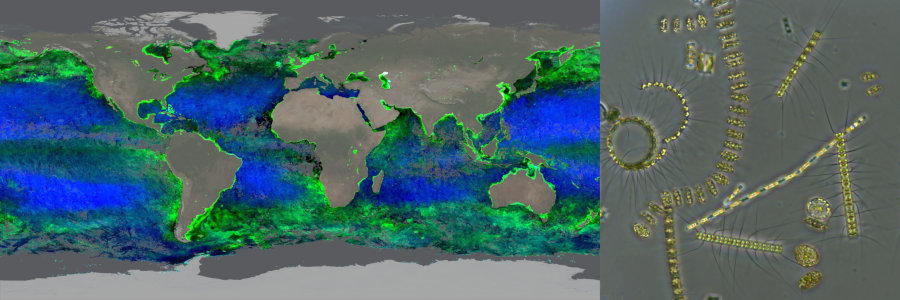![](phytoplankton.jpeg)

Image credit: https://oceandata.sci.gsfc.nasa.gov/gallery/778/ and Wikipedia

From a scientific perspective, we can treat the ocean as a complex chemical system where the following measurements act as our inputs and outputs:

* Environmental Factors (our input features)

    *   **Sea Surface Temperature (SST) [°C]**: A measure of the thermal energy at the ocean's surface. Temperature controls the metabolic rates of phytoplankton.

    *   **Nutrient Levels [mg/L]:** Measures the concentration of essential elements like nitrogen, phosphorus, and iron. In many parts of the ocean, phytoplankton growth is "nutrient-limited," meaning they have enough light for photosynthesis but lack the nutrients to reproduce.

    *   **Sunlight Hours [h]:** Phytoplankton are photosynthetic. This variable represents the duration of available sunlight. Without sufficient light, the biological process of converting $\text{CO}_2$ into organic matter stops.

    *   **Ocean Region [Categorical]:** Geographic metadata that describes that region of ocean. Can be coastal, open ocean, or upwelling zone. An upwelling zone is where cold and nutrient-rich water from the deep ocean has risen to the surface.

    *   **Weather Condition [Categorical]:** Sunny, cloudy, or stormy.

* Target (the output we are trying to predict)
    *   **Phytoplankton Concentration [mg/m³]:** Usually measured via Chlorophyll-a fluorescence. This is our dependent variable ($y$), the value we aim to predict based on the environmental conditions above.

## 2. Libraries & Tools
Before we begin any work, it is standard to import the required libraries into our project. Here we will use a number of libraries that make up the standard Python data science stack for machine learning. Let's discuss what each one does:

* Math, Vectors, and Data

    * **NumPy** (`np`): The fundamental library for scientific computing. It handles large, multi-dimensional vectors, arrays and matrices. In comparison to built-in Python data types, NumPy arrays are more efficient in memory allocation and generally better for storing large list of numbers.

    * **Pandas** (`pd`): Provides a `DataFrame`, which is a tabular data structure (similar to an Excel spreadsheet) that allows for easy data manipulation, cleaning, and retrieval.

* Visualization

    * **Matplotlib** (`plt`): The base library for creating data visualizations in Python.

    * **Seaborn** (`sns`): Built on top of Matplotlib, it provides more advanced visualization features when creating plots.

* Machine Learning

    * The machine learning library that we will be using today is called **scikit-learn**. It is a very popular machine learning framework with ready-to-use implementations for regression and classification. You can read more about it here: https://scikit-learn.org/stable/supervised_learning.html. The functions that we will use are listed below.

    * **Preprocessing** (`SimpleImputer`, `StandardScaler`, etc.): Tools to impute data (i.e., fill in missing data values) and normalize features to expected ranges so that the ML model can process them efficiently.

    * **Pipelines and Transformers** (`Pipeline`, `ColumnTransformer`): Functions that allow us to connect different preprocessing steps together and apply them to our data. Essential for avoiding data leakage and reducing code complexity.

    * **Data Splitting** (`train_test_split`): Function for splitting data into different subsets for training and testing the ML model.

    * **Hyperparameter Tuning** (`GridSearchCV`, `BayesSearchCV`): Tools for systematically testing different model "hyperparameters" to identify the optimally-performing model.

    * **Evaluation Metrics** (`mean_squared_error`, `r2_score`): Measurements of the accuracy of our model, and how well it describes the variance in the data.

    * **Regression** (`RandomForestRegressor`): ML model that we will be using in this lesson. Specifically, this model partitions the data into smaller subsets and calculates an average value within each subset.

#### Importing the Libraries

Here we will load the necessary libraries.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV

In [ ]:
# uncomment to suppress Python warnings
#import os, warnings
#os.environ["PYTHONWARNINGS"] = "ignore::UserWarning"
#warnings.filterwarnings("ignore")

#### Defining Custom Functions

Here we will define custom functions to plot histograms for our data. There are separate functions for numerical distributions (i.e., variables that are described by a number) and for categorical distributions (i.e., variables that are described by a category).

In [2]:
def plot_numerical_distributions(df, bins=30):
    # plot the distribution of all numerical features in the input dataframe

    num_cols = df.select_dtypes(include=['number']).columns  # select numerical columns
    num_features = len(num_cols)

    if num_features == 0:
        print("No numerical features found in the DataFrame.")
        return

    # define the number of rows and columns for subplots
    rows = (num_features + 1) // 2  # 2 plots per row
    fig, axes = plt.subplots(rows, 2, figsize=(10, 5 * rows))  # dynamic grid
    axes = axes.flatten() if num_features > 1 else [axes]  # flatten if multiple plots

    for i, col in enumerate(num_cols):
        sns.histplot(df[col].dropna(), bins='sqrt', kde=False, ax=axes[i], color="steelblue")
        axes[i].set_title(f"Distribution of {col}", fontsize=12)
        axes[i].set_xlabel("")
        axes[i].set_ylabel("Count")

    # remove empty subplots
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

def plot_categorical_distributions(df):
    # plot the distribution of all categorical features in the input dataframe

    cat_cols = df.select_dtypes(include=['object', 'category']).columns  # select categorical columns
    cat_features = len(cat_cols)

    if cat_features == 0:
        print("No categorical features found in the DataFrame.")
        return

    # define the number of rows and columns for subplots
    rows = (cat_features + 2) // 3  # 3 plots per row
    fig, axes = plt.subplots(rows, 3, figsize=(15, 5 * rows))  # dynamic grid
    axes = axes.flatten() if cat_features > 1 else [axes]  # flatten if multiple plots

    for i, col in enumerate(cat_cols):
        sns.countplot(data=df, x=col, ax=axes[i], palette="Set2",hue = col, legend = False)
        axes[i].set_title(f"Distribution of {col}", fontsize=12)
        axes[i].set_xlabel("")
        axes[i].set_ylabel("Count")
        axes[i].tick_params(axis='x', rotation=90)  # rotate labels for readability

    # remove empty subplots
    for j in range(i + 1, len(axes)):
        fig.delaxes(axes[j])

    plt.tight_layout()
    plt.show()

def residual_plot(y_test_pred, y_test,subtitle = ''):
    # create a figure with 2 rows, 1 column

    # height_ratios=[3, 1] makes the top plot 3x taller than the bottom one
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 12), sharex=True, gridspec_kw={'height_ratios': [3, 1]})

    # --- Subplot 1: Actual vs. Predicted ---
    ax1.scatter(y_test_pred, y_test, alpha=0.3, color='teal', label="Test Points")
    ax1.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label="Ideal Fit")
    ax1.set_ylabel("Actual Concentration (mg/m$^3$)")
    ax1.set_title(f"Model Performance Diagnostics: Phytoplankton Prediction {subtitle}", fontsize=14)
    ax1.legend()
    ax1.grid(True, linestyle=':', alpha=0.6)

    # --- Subplot 2: Residual Analysis ---
    residuals = y_test.values.ravel() - y_test_pred
    ax2.scatter(y_test_pred, residuals, alpha=0.3, color='purple')
    ax2.axhline(y=0, color='black', linestyle='--')
    ax2.set_xlabel("Predicted Concentration (mg/m$^3$)")
    ax2.set_ylabel("Residual (Error)")
    ax2.set_title("Residual Analysis (Diagnostic)")
    ax2.grid(True, linestyle=':', alpha=0.6)

    plt.tight_layout()
    plt.show()

#### Loading the Dataset

Finally, we load the oceanography dataset. This dataset has been created by running the separate script called `generate_ocean_data.py` to simulate environmental conditions along with phytoplankton concentrations. Using this dataset, we will construct a machine learning model that can accurately predict the phytoplankton concentration for a given set of environmental conditions.

In [ ]:
# Your code goes here

for col in data.columns:
    num_nans = data[col].isna().sum()
    # print(f"{col}: {num_nans} NaNs")
    print(f"{col}")
else:
    print(f'\nTOTAL SAMPLES: {data.shape[0]}')

## 3. Exploratory Data Analysis (EDA)

Before we start building our machine learning model, we want to have a basic understanding of our data. This step in the machine learning workflow is called **exploratory data analysis** or **EDA**.

Let's discuss the 3 pillars of EDA:

#### **Pillar 1: Distribution and Shape of Data**

Before modeling the data, we want to understand the characteristics of each feature. We can look at:

- *Central Tendency and Spread*
    - Where is the average value for each feature, and what is the spread? How many are far away from the average?
    - For example, if `feature1` ranges from 0−1000, and `feature2` ranges from 50−55, an ML model might think `feature1` is much more important just because the values are higher. In this case, we may want to rescale that data so that the features lie within a comparable range.
- *Skewness*:
    - Is the data symmetric about the average, or is it weighted to one side?
    - Skewed data means there can be outliers that distort the model's predictions.
    - For example, if a feature's distribution is skewed to the right, we might apply a logarithmic transformation to that feature to make the distribution less asymmetric.
- *Modality*:
    - Does the data have one peak (unimodal), two peaks (bimodal), or many peaks (multimodal)?
    - For example, a bimodal distribution may suggest that the feature has two underlying distributions which are superposed.

#### **Pillar 2: Coupling and Relationships Between Variables**

We want to understand the dependency relationship between the features in the dataset.

- *Correlation*:
    - Do the variables move together?
    - For example, if `feature1` goes up, does `feature2` tend to go up as well? What about `feature1` and the target variable?
    - Correlation allows us to understand which features have the strongest influence on the target.
- *Redundancy*:
    - Are two features very highly correlated? If so, they might be redundant.
    - For example, if your dataset contains similar measurements from two different sensors, you may only want to include the data from one of these sensors when training the model.
    - Eliminating redundant features can result in a simpler machine learning model. This is important for reducing computational cost and for allowing easier interpretation of the model's predictions.

#### **Pillar 3: Data Quality and Completeness**

Machine learning follows the concept of "garbage in, garbage out", meaning that flawed or poor-quality data can result in meaningless predictions. We must make an effort to identify potential problems in the data.

- *Outliers*
    - Are there any impossible readings that will skew our model?
    - For example, a few extreme outliers can bias the model's training and result in poor real-world predictions.
- *Missing Data*
    - Are there `NaN` or empty values in the data?
    - Most ML algorithms cannot process `NaN`, so we typically want to do something about those entries (such as discarding or imputing new values) while keeping the rest of the dataset intact.
- *Cardinality*:
    - For categorical data, do we have enough samples from that category to perform a meaningful analysis?
    - Cardinality refers to the number of unique values in a specific column of the dataset. If a category does not have enough unique values, we may not be able to draw statistical conclusions from it.

As a first step in EDA, we can try looking at a few sample values.

In [ ]:
# Your code goes here

In [ ]:
# Your code goes here

We can also try plotting the distribution of values for each feature.

In [ ]:
plot_numerical_distributions(data)
plot_categorical_distributions(data)

We can also try plotting different features against each other to get a glimpse at the potential relationships between variables.

In [ ]:
sst = # Your code goes here
nutrient_levels = # Your code goes here
sunlight_hours = # Your code goes here
phyto_concentration = # Your code goes here

# stack the features together
X_plot = np.vstack((sst, nutrient_levels, sunlight_hours)).T
y_plot = np.array(phyto_concentration).reshape(-1, 1)

feature_names = ['SST (°C)', 'Nutrient Levels', 'Sunlight Hours']
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for i in range(X_plot.shape[1]):
    axes[i].scatter(X_plot[:, i], y_plot, alpha=0.6)
    axes[i].set_xlabel(feature_names[i])
    axes[i].set_title(f'Phyto Conc. vs {feature_names[i]}')
    axes[i].grid(True)

axes[0].set_ylabel('Phytoplankton Concentration')
plt.tight_layout()
plt.show()

## 4. Interpreting the Feature Correlation Matrix

A correlation matrix is a critical diagnostic tool used to understand the linear relationships between numerical variables. It calculates the **Pearson Correlation Coefficient ($r$)**, which quantifies the strength and direction of a relationship between two variables.

#### How to Read the Values
The values in the matrix range from $-1.0$ to $+1.0$:
* **$+1.0$: Perfect Positive Correlation** (as `feature1` increases, `feature2` increases in a perfectly linear fashion).
* **$0.0$: No Linear Correlation** (there is no linear relationship). Note that a value of $0.0$ does not mean there is no relationship; it just means the relationship isn't a straight line.
* **$-1.0$: Perfect Negative Correlation** (as `feature1` increases, `feature2` decreases in a perfectly linear fashion).

#### Things to Look For
1. **Feature-to-Target Correlation:**
Look at the row or column for `Phytoplankton_Concentration`. High absolute values (e.g., $> |0.6|$) indicate strong predictors. These are the "signals" your model may rely on to make predictions.

2. **Multicollinearity (Feature-to-Feature Correlation):**
Look for high correlations between your *inputs* (e.g., if `Nutrient_Levels` and `SST` were $0.95$).
    * **Redundancy:** In physics-based modeling, this could indicate redundant sensors measuring the same process.
    * **Interpretation:** While our machine learning model could be robust against this, highly redundant features can make it harder to calculate exactly which one is "most important".
3. **The Diagonal Line:**
You will notice a diagonal line of **$1.00$**. This is simply because each variable is perfectly correlated with itself.

In [ ]:
# plot the feature correlation matrix with Seaborn
plt.figure(figsize=(14, 10))
sns.heatmap(data.select_dtypes(include=[np.number]).corr(),
            annot=True, cmap='viridis', fmt='.2f',    # use the 'viridis' colour map with annotations
            annot_kws={"size": 20},                   # adjust annotation font size
            linewidths=0.5, linecolor='gray')         # add gridlines for spacing
plt.title('Feature Correlation Matrix', fontsize=16)  # increase title font size
plt.xticks(rotation=45, ha='right', fontsize=10)      # rotate x-axis labels for readability
plt.yticks(fontsize=10)                               # adjust y-axis label font size
plt.show()

## 5. Data Preprocessing with `sklearn` Pipelines

In a machine learning workflow, we want to prioritize modularity and reproducibility. Instead of cleaning our data manually, we can use scikit-learn's `pipeline` and `ColumnTransformers` to create an "assembly line" for our data. This approach ensures that any transformations that we want to make to our data will be applied consistently and efficiently, making our workflow easier to maintain and modify later.

#### Components of Preprocessing

* **`Pipeline`**: Define a sequence of data transformations where the outputs of one step become the inputs of the next step. This allows us to make sure that the order of data operations is always consistent.

* **`SimpleImputer`**: Fill in the missing values in a dataset ("imputation") using a specific strategy. For numerical data, we will use the `mean` strategy and for categorical features we use the `most_frequent` strategy.

* **`StandardScaler`**: Normalize and scale each numerical feature so that it has zero mean and a standard deviation equal to one. This prevents features with large relative values from numerically dominating the other features in the dataset.

* **`Encoder`**: Convert categorical data into numerical values so that the machine learning model can effectively process it. There are several possible strategies for doing so.

    * **`OrdinalEncoder`**: Convert each possible category into numbers based on a logically-ordered list (e.g., `small -> 0`, `medium -> 1`, `large -> 2` so that larger sizes correspond to larger numbers).

    * **`OneHotEncoder`**: Convert each possible category into numbers using separate binary columns, assuming no inherent order (e.g., `red -> [1,0,0]`, `green -> [0,1,0]`, `blue -> [0,0,1]` since there is no "natural" way to rank colours in an ascending order).

* **`ColumnTransformer`**: Combine the different preprocessing components and select which features each component will be applied to.

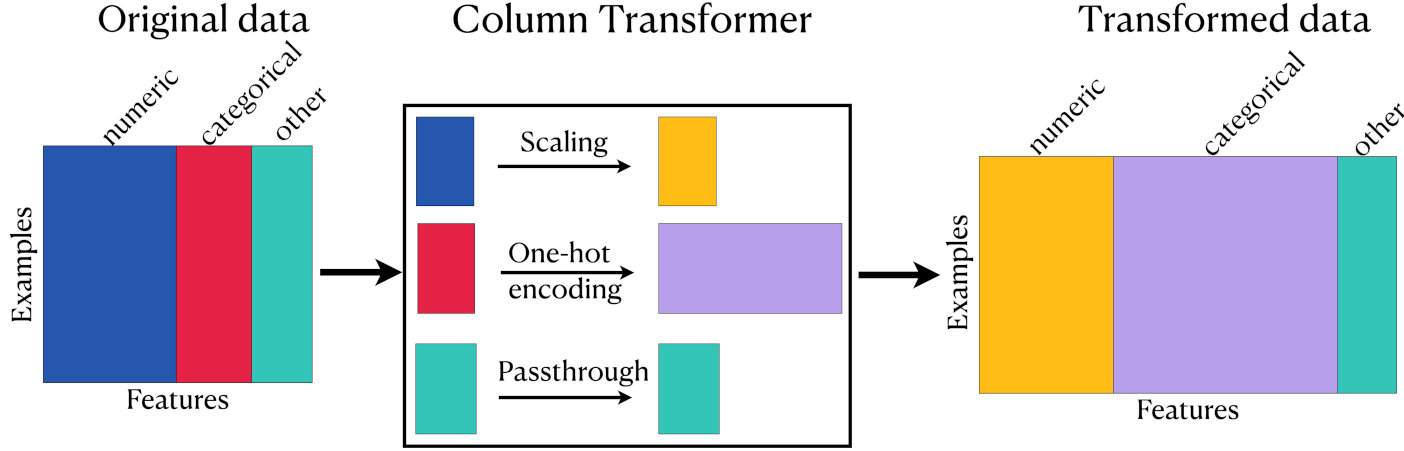

Image credit: https://amueller.github.io/COMS4995-s20/slides/aml-04-preprocessing/

In [ ]:
# create the data preprocessing pipeline

# define X and y from data
features = ['Sea_Surface_Temperature',
            'Nutrient_Levels',
            'Sunlight_Hours',
            'Ocean_Region',
            'Weather_Condition']
target = ['Phytoplankton_Concentration']

X = data[features]
y = data[target]

# define numerical, ordinal, and nominal features
numerical_cols = # Your code goes here
ordered_cat_cols = # Your code goes here
nonordered_cat_cols = # Your code goes here

# define each pipeline step
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('scaler',  StandardScaler())
])

ordered_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(categories=[['stormy', 'cloudy', 'sunny']]))
])

nonordered_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown = 'ignore'))
])

# combine pipelines into a preprocessor object
preprocessor = ColumnTransformer(transformers = [
    ('num', num_pipeline, numerical_cols),
    ('ordered_cat', ordered_pipeline, ordered_cat_cols),
    ('nonordered_cat', nonordered_pipeline, nonordered_cat_cols)
])

## 6. Data Splitting

When evaluating a machine learning model, the performance should be judged on data it has never seen before. One strategy for measuring this performance is to split the dataset into two parts: a **training set** which is used for teaching the model to make predictions, and a **test set** which is used only to evaluate its performance on unseen data.

Why do we want to do this? Sometimes, a model can perform very well on the data it was trained on simply by memorizing it (including its random noise) without learning the true underlying relationships. This is called **overfitting**. A model that has overfit will score highly on its training data but make poor predictions on new data. Evaluating on a held-out test set tells us how well the model generalizes to unseen data. A large gap between the training score and the held-out score is a warning sign of overfitting.

In scikit-learn, we can use `train_test_split` to perform the data splitting. Note that we will only "fit" our data transformations defined via the data processing pipeline *after* we have performed the data splitting. This is to prevent "data leakage", where data points from the test set influence the training process (for example, through the mean value used to fill in missing points during data imputation). If not handled properly, data leakage can make the model appear better than it actually is.

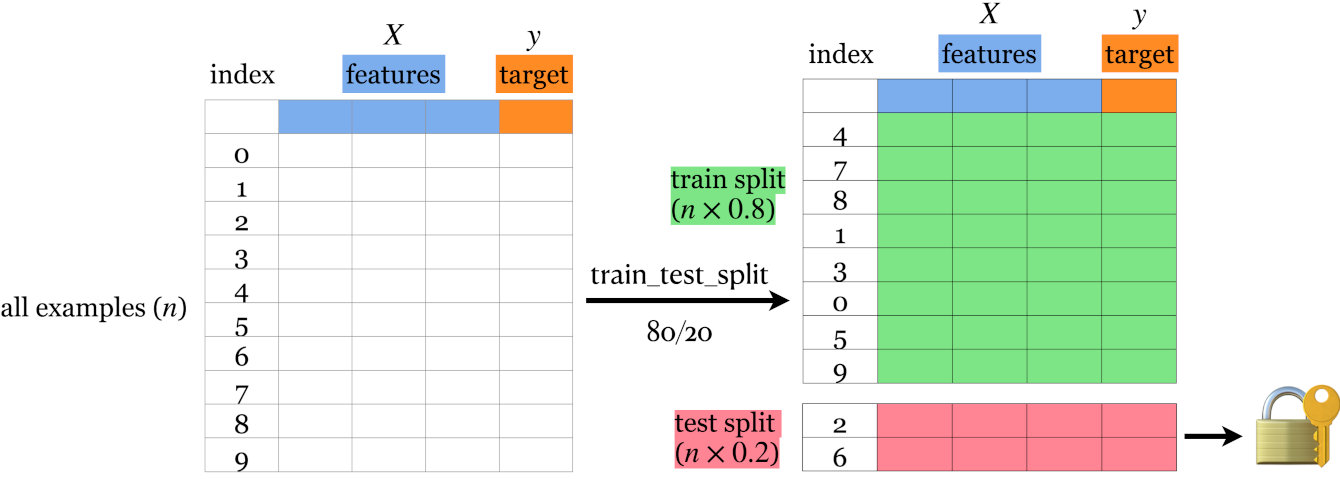

Image credit: https://github.com/UBC-CS/cpsc330-2022W1/blob/dfe6a227f5ddb593bcc4ff1e83dda2750a37aecc/lectures/03_fundamental-tradeoff.ipynb

In [ ]:
# split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    # Your code goes here
                                                    )

In [ ]:
# fit the preprocessor on the training data only, then apply it to both sets (this converts them to NumPy arrays)
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

As a quick check of our work so far, we can plot the correlation matrix again for the processed training features.

In [ ]:
X_for_corr = pd.DataFrame(X_train, columns=preprocessor.get_feature_names_out())

plt.figure(figsize=(14, 10))
sns.heatmap(X_for_corr.corr(),
            annot=True, cmap='viridis', fmt='.4f',               # use the 'viridis' colour map with annotations
            vmin=-1, vmax=1,                                     # fix the color scale to the full correlation range
            annot_kws={"size": 20},                              # adjust annotation font size
            linewidths=0.5, linecolor='gray')                    # add gridlines for spacing
plt.title('Feature Correlation Matrix: Processed', fontsize=16)  # increase title font size
plt.xticks(rotation=45, ha='right', fontsize=10)                 # rotate x-axis labels for readability
plt.yticks(fontsize=10)                                          # adjust y-axis label font size
plt.show()

## 7. The Random Forest Regressor

Having preprocessed our data, it is now time to train the model. While there are many possible models we can choose from, we will use `RandomForestRegressor` in scikit-learn. This is an ensemble method which combines multiple decision trees into a **random forest**, which helps to reduce overfitting.

How does this work? Recall that a single decision tree makes a prediction by asking a series of yes/no questions about the features, which splits the data into smaller and smaller groups. For example: Is the sea surface temperature greater than 20 °C? If yes, are the nutrient levels greater than 2 mg/L? And so on. Once a sample has been sorted into a final group, the tree predicts the average phytoplankton concentration of the training samples that were sorted into that same group. A single tree can easily overfit, so a random forest contains many trees (each on a randomly resampled version of the training data) and averages their predictions. Combining many models like this is called an **ensemble**, and it gives more stable predictions than any one tree.

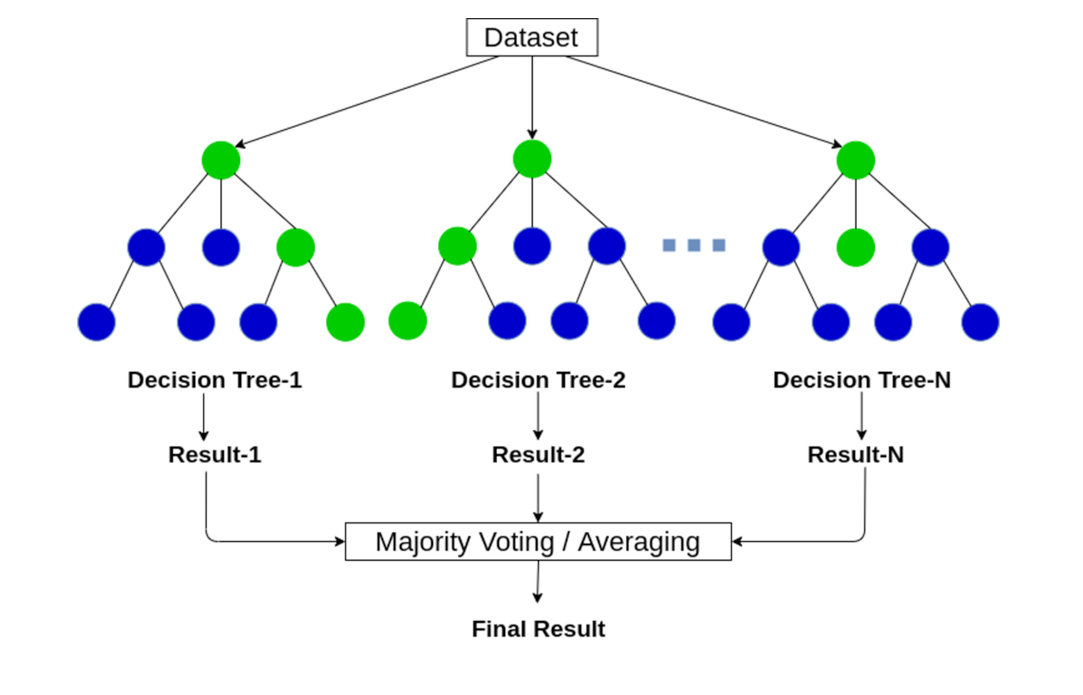

Image credit: https://anasbrital98.github.io/blog/2021/Random-Forest/

When configuring `RandomForestRegressor`, we use several "hyperparameters" to control the complexity and performance of the model.

* **`n_estimators`** (default=100): The number of trees in the forest. According to the [scikit-learn documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html), more trees generally leads to a more stable model, though it requires more memory and computation time.

* **`max_depth`**: This limits how deep each tree can grow. While the default is `None` (allowing trees to grow until they are fully "pure"), setting a limit like `10` is a form of **regularization** that prevents the model from becoming too complex and overfitting to the training data.

* **`min_samples_split`**: The minimum number of data points required to split an internal node. Increasing this number ensures that the model only makes decisions based on significant "clusters" of data rather than individual noisy samples.

* **`max_features`**: This determines how many features are evaluated when looking for the best split at each node.

    * Setting this to `1.0` means the model looks at every single feature (SST, Nutrients, etc.) for every split.

    * Reducing this (e.g., to `'sqrt'` or `0.5`) introduces more randomness into the trees, which can help decorrelate them and improve the overall ensemble performance.

* **`random_state`**: Machine learning models often involve random number generation (for instance, when randomly selecting subsets of data). By setting a **seed** for the random number generator (e.g., `1997`), we ensure that the random process is reproducible. This is vital for validating the results.

* **`n_jobs`**: A performance optimization. Setting this to `-1` tells the computer to use all available CPU cores to build the trees in parallel, significantly speeding up the training process.

* **`verbose`**: Controls the amount of text output during training. For long-running engineering simulations, `verbose=1` provides a progress bar or status updates so you know the model is still processing.

Note that we will initially set the hyperparameters of `RandomForestRegressor` ourselves, but later on, we will introduce a method to systematically tune these to their optimal values.

In [ ]:
# define the random forest regressor model
rf_model = RandomForestRegressor(
    n_estimators=       # Your code goes here    # number of trees in the forest (more trees ~= more stable, but slower and more RAM)
    max_depth=          # Your code goes here    # how deep each tree can grow ('None' often leads to overfitting)
    min_samples_split=  # Your code goes here    # minimum samples required to split a node (prevents splitting on noise)
    max_features =      # Your code goes here    # maximum number of features to consider when looking for the best split at each tree node
    random_state=1997,     # seed for random number generation
    n_jobs=-1,             # use all CPU cores for parallel tree building (significant speedup)
    verbose=1              # print progress during training
)

In [ ]:
# fit the model and make predictions on the test set
rf_model.fit(X_train,y_train.values.ravel())

y_test_pred  = rf_model.predict(X_test)
y_train_pred = rf_model.predict(X_train)

To evaluate model performance in a regression task, we can compare the true values of data points ($y_i$) in the test set to the values predicted by the model ($\hat{y}_i$). There are several ways to make this comparison:

* **Root Mean Squared Error (RMSE)**: $$\text{RMSE} = \sqrt{\frac{1}{n} \sum_{i=1}^n (y_i - \hat{y}_i)^2}$$

* **Coefficient of Determination ($R^2$)**: $$R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}$$

RMSE is useful for measuring the average magnitude of the model's prediction errors in the same units as the target variable (with larger errors penalized more heavily). On the other hand, $R^2$ is useful for evaluating how well the model explains variations in the target variable (when compared against a simplistic model that always predicts the average, $\bar{y}$).

In [ ]:
# evaluate model performance
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
test_r2 = r2_score(y_test, y_test_pred)

train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
train_r2 = r2_score(y_train, y_train_pred)

print(f"Training   | RMSE: {train_rmse:.4f}, R2: {train_r2:.4f}")
print(f"Test       | RMSE: {test_rmse:.4f}, R2: {test_r2:.4f}")

We can also look at **feature importance**, which tells us how much each input feature contributes to a model's predictions. Specifically, scikit-learn's `rf_model.feature_importances_` is computed during training and shows which features the model relied on most when making splits. However, it does not prove that a specific feature causes changes in the target.

In [ ]:
# extract the feature names from the preprocessor
feature_names_out = preprocessor.get_feature_names_out()

# plot the most influential features
importances = pd.Series(rf_model.feature_importances_, index=feature_names_out)
plt.figure(figsize=(10, 6))
importances.sort_values(ascending=True).tail(10).plot(kind='barh', color='seagreen')
plt.title('Feature Importance: Which "Sensors" Matter Most?')
plt.xlabel('Relative Importance')
plt.show()

## 8. Model Performance Diagnostics

Having trained our random forest model, we can attempt to visualize its performance. While metrics like $R^2$ and RMSE have helped provide an initial check, we also want to know where our model succeeds, where it fails, and if there are any systematic errors.

In the plots below, the top panel shows the relationship between the "true" measurements ($y_i$) and the values predicted by the model ($\hat{y}_i$). Here are a few things to keep in mind:
* The red dashed line represents the relationship $y = \hat{y}$, which corresponds to a model that predicts each sample perfectly. If every point was on this line, our model would have $R^2 = 1.0$.
* Points above the red line indicate that the model predicted less phytoplankton than was actually present (i.e., the model made an underestimate).
* Points below the red line indicate that the model predicted more phytoplankton than was actually present (i.e., the model made an overestimate).
* Ideally, we want to see a tight cluster of points along the diagonal. For instance, if the cluster curved away from the line at high values, it would suggest that the model "saturates" and fails at predicting more extreme values.

The bottom panel of the plot shows the vertical difference between the actual value and the predicted value (called the **residual**).
* A perfect prediction has a residual of zero (i.e., a horizontal line).
* In a healthy model, the purple dots should be randomly scattered around the horizontal zero-line with a consistent spread (**homoscedasticity**). This indicates that our model's error is just random noise.
* If the spread tended to get wider as the predicted concentration increased, this would be an example of **heteroscedasticity**. It means our model is less certain at higher concentrations.
* If the residuals followed a curve, it would suggest that the model has missed a fundamental non-linear physical relationship in the data. This is a sign we might need to tune our `max_depth` or check for a missing feature.

Overall, these plots help us determine if our error is truly random or if there is a systematic flaw in our model.

In [ ]:
residual_plot(y_test_pred, y_test, subtitle = '(Initial Model)')

## 9. Hyperparameter Tuning & Cross-Validation

Recall that hyperparameters are the parameters set by the researcher when the model is defined (i.e., they are the parameters which are not learned during training). If we want to find the most accurate and robust model, we can systematically test different combinations of hyperparameters instead of just guessing and checking.

There are several ways to do this. The simplest method is **grid search**. With this method, we create a grid of possible hyperparameter values that we want to test. The `GridSearchCV` method in scikit-learn tests every single possible combination to find the best one for a given choice of the evaluation metric. The main tradeoff of this search is a higher computational cost (and this gets worse as the number of parameters grows).

For our model, we will test:
*   3 values for `n_estimators`
*   4 values for `max_depth`
*   3 values for `min_samples_split`
*   3 values for `max_features`

This results in $3 \times 4 \times 3 \times 3 = 108$ different model configurations to be tested.

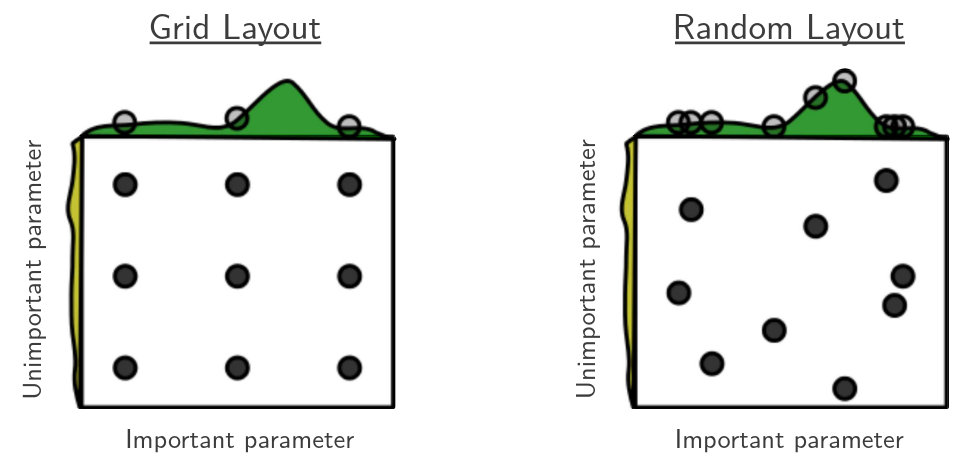

Image credit: J. Bergstra and J. Bengio, <i>Random search for hyper-parameter optimization</i>, J. Mach. Learn. Res. <b>13</b>, 281–305 (2012)

During hyperparameter tuning, we test the performance of the model on a random subset of the training data. This subset of data is called the **validation set**. By rotating through different combinations of training and validation sets, we can average out the randomness which might be introduced through any specific split. This process is known as **$k$-fold cross-validation**.

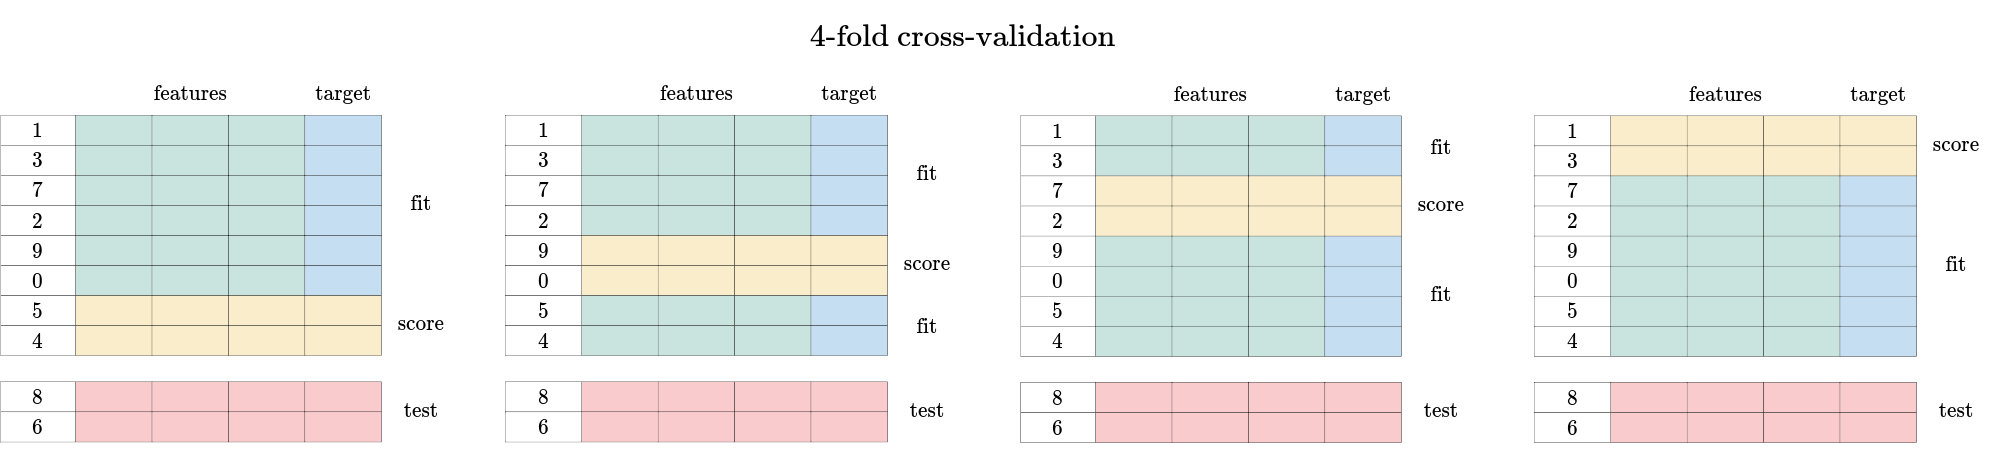

Image credit: https://github.com/UBC-CS/cpsc330-2022W1/blob/dfe6a227f5ddb593bcc4ff1e83dda2750a37aecc/lectures/03_fundamental-tradeoff.ipynb

 In scikit-learn, we can use the `GridSearchCV` method to perform grid search with cross-validation. We will use `cv=5` (i.e., 5-fold cross-validation) which results in each of the 108 hyperparameter combinations being evaluated on 5 different splits of the data. This means that we are actually testing 540 model fits!

We must also select a metric which serves as the basis for comparison. In this case, we will use the average $R^2$ score across all folds for a given hyperparameter combination.

**NOTE:** Due to the large number of fits required in hyperparameter tuning, this step may take a long time. The time requirements will also depend on the the computing resources available to you. To speed things up, I've introduced a "mini" version of this grid search in the code below. On my Dell laptop, the full grid search takes 1.5 minutes using 12 cores; on Google Colab free tier, the same search takes 21 minutes using 2 cores!

In [ ]:
# choose between "full" and "mini" grid search
SEARCH_MODE = "mini"

# "full" grid search (540 model fits)
if SEARCH_MODE == "full":
    param_grid = {
        'n_estimators': [100, 200, 300],       # testing to see if more trees will improve stability
        'max_depth': [5, 10, 15, 20],          # testing different tree depths
        'min_samples_split': [2, 5, 10],       # testing different splitting sensitivities
        'max_features': ['sqrt', 'log2', 1.0]  # testing different numbers of features to consider at each split of each tree
    }
    cv_folds = 5                               # number of cross-validation folds

# "mini" grid search (48 model fits)
elif SEARCH_MODE == "mini":
    param_grid = {
        'n_estimators': [100, 200],    # testing to see if more trees will improve stability
        'max_depth': [5, 15],          # testing different tree depths
        'min_samples_split': [2, 10],  # testing different splitting sensitivities
        'max_features': ['sqrt', 1.0]  # testing different numbers of features to consider at each split of each tree
    }
    cv_folds = 3                       # number of cross-validation folds

else:
    raise ValueError("SEARCH_MODE must be 'full' or 'mini'")

# initialize the base model
rf_base = RandomForestRegressor(random_state=1997)
grid_search = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid,
    cv=cv_folds,            # use 5-fold cross validation
    scoring='r2',           # use R^2 as the evaluation metric
    verbose=2,              # print progress during search
    n_jobs=-1               # parallelize the search
)

# perform the search
grid_search.fit(X_train, y_train.values.ravel())


In [ ]:
# extract optimal hyperparameters
print(f"Best Parameters: {grid_search.best_params_}")
print(f'Best CV Score (R^2): {grid_search.best_score_:.4f}')

# the best model is already "fitted" and ready to use
best_model = grid_search.best_estimator_
y_test_pred = best_model.predict(X_test)

residual_plot(y_test_pred,y_test,subtitle='(Grid Search Optimized)')

Another simple method for hyperparameter tuning is **random search**. Although we won't explore the method here, it works by randomly selecting hyperparameter combinations within the specified ranges.

## Extra: Advanced Hyperparameter Tuning

While grid search is thorough, it can also be wasteful by spending too much time on irrelevant hyperparameter combinations. To be more efficient, we can use **Bayesian optimization** with scikit-optimize's `BayesSearchCV`. There are several advantages to this approach:
* **Automation**: Unlike grid search, Bayesian optimization builds a probabilistic model of the search space by "learning" from previous iterations. This means that it can spend more time on the most promising regions of the hyperparameter space.
* **Ranged Search**: Unlike grid search, which requires us to manually select the hyperparameters values (e.g., `[10, 50, 100]`), a Bayesian approach can automatically determine the optimal values within a specified range (e.g., `Real(10,100)` or `Integer(10,100)`).
* **Model Efficiency:** The flexibility of Bayesian optimization can often result in a machine learning model with better overall performance due to its precise selection of the final hyperparameters.

There are also a few downsides to Bayesian optimization:
* **Time**: Due to the sequential nature of this method, it can be difficult or impossible to run the searches in parallel. This can drastically increase computation time.
* **Complexity**: Behind the scenes, `BayesSearchCV` builds a surrogate machine learning model which guesses the next hyperparameter combination. This can add additional overhead which grows with the number of iterations.
* **Interpretability**: Unlike grid search, which is guaranteed to find the best combination on its grid, Bayesian optimization can be less predictable; it may be difficult to understand why it picked a given combination.

In [ ]:
# install and load extra libraries
!pip install scikit-optimize
from skopt import BayesSearchCV
from skopt.space import Real, Categorical, Integer
from skopt.plots import plot_convergence

# choose between "full" and "mini" Bayesian search
SEARCH_MODE = "mini"

# define the parameter space (some combinations within this space will be tested)
search_space = {
    'n_estimators': Integer(100,500, prior = 'log-uniform'),  # this prior searches in a logarithmic fashion
    'max_depth': Integer(5,30, prior = 'uniform'),            # this prior searches in a uniform fashion
    'max_features': Real(0.1,1.0, prior = 'uniform')
}

# "full" Bayesian search (250 model fits)
if SEARCH_MODE == "full":
    n_iter = 50
    cv_folds = 5

# "mini" Bayesian search (45 model fits)
elif SEARCH_MODE == "mini":
    n_iter = 15
    cv_folds = 3

else:
    raise ValueError("SEARCH_MODE must be 'full' or 'mini'")

# initialize the base model
rf_base = RandomForestRegressor(random_state=1997)

# perform the search
bayes_search = BayesSearchCV(
    estimator=rf_base,
    search_spaces=search_space,
    n_iter=n_iter,     # number of hyperparameter combinations to try
    cv=cv_folds,       # number of cross-validation folds
    scoring='r2',      # use R^2 as the evaluation metric
    verbose=2,         # print progress during search
    n_jobs=-1,         # parallelize the search
    random_state=1997  # seed for random number generation
)

# fit the model
bayes_search.fit(X_train, y_train.values.ravel())

In [ ]:
# extract optimal hyperparameters
print(f'Best Parameters: {bayes_search.best_params_}')
print(f'Best CV Score (r^2): {bayes_search.best_score_:.4f}')

# the best model is already "fitted" and ready to use
best_rf_bayes = bayes_search.best_estimator_
y_test_pred_bayes = best_rf_bayes.predict(X_test)

To visualize these results, we can also use scikit-optimize's `plot_convergence` along with our custom `residual_plot`

In [ ]:
plot_convergence(bayes_search.optimizer_results_)
plt.title("Bayesian Optimization Convergence")
plt.show()

residual_plot(y_test_pred_bayes,y_test,subtitle='(Bayes Search Optimized)')

## Summary

In this case study, we worked through a machine learning project from start to finish. Using an oceanography dataset, we first conducted an exploratory data analysis to understand the distribution, quality, and relationships within our data. Next, we preprocessed and split the data to facilitate training with a random forest regression model. Finally, we tuned the model's hyperparameters using a grid search method and a Bayesian method. Overall, the final model explained about 90% of the variation in the oceanography variable that we were trying to predict.

Regardless, the same workflow of exploring, preprocessing, splitting, training, evaluating, and tuning in this notebook can apply to many different datasets that you might want to work with!